<a href="https://colab.research.google.com/github/jyothish2k99/Fake_News_Misinformation_Detection/blob/main/internship_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import zipfile

with zipfile.ZipFile("/content/True.csv.zip", "r") as zip_file:
    zip_file.extractall("true_data")

with zipfile.ZipFile("/content/Fake.csv.zip", "r") as zip_file:
    zip_file.extractall("fake_data")

print("Both datasets extracted successfully!")

Both datasets extracted successfully!


In [3]:
import pandas as pd

true_df = pd.read_csv("true_data/True.csv")
fake_df = pd.read_csv("fake_data/Fake.csv")

print("Real news dataset:")
display(true_df.head())

print("Fake news dataset:")
display(fake_df.head())

Real news dataset:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


Fake news dataset:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [4]:
print("Real news shape:", true_df.shape)
print("Fake news shape:", fake_df.shape)

Real news shape: (21417, 4)
Fake news shape: (23481, 4)


In [5]:
print("Real news columns:")
print(true_df.columns)

print("\nFake news columns:")
print(fake_df.columns)

print("\nReal news information:")
true_df.info()

print("\nFake news information:")
fake_df.info()

Real news columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')

Fake news columns:
Index(['title', 'text', 'subject', 'date'], dtype='object')

Real news information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB

Fake news information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [6]:
missing_report = pd.DataFrame({
    "Real_Missing": true_df.isnull().sum(),
    "Real_Missing_%": (
        true_df.isnull().mean() * 100
    ).round(2),
    "Fake_Missing": fake_df.isnull().sum(),
    "Fake_Missing_%": (
        fake_df.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

,Real_Missing,Real_Missing_%,Fake_Missing,Fake_Missing_%
title,0,0.0,0,0.0
text,0,0.0,0,0.0
subject,0,0.0,0,0.0
date,0,0.0,0,0.0


In [8]:
print("Real exact duplicate rows:", true_df.duplicated().sum())
print("Fake exact duplicate rows:", fake_df.duplicated().sum())


Real exact duplicate rows: 206
Fake exact duplicate rows: 3


In [11]:
print("Real News Data Types:")
display(true_df.dtypes.to_frame("Data Type"))

print("Fake News Data Types:")
display(fake_df.dtypes.to_frame("Data Type"))


Real News Data Types:


,Data Type
title,object
text,object
subject,object
date,object


Fake News Data Types:


,Data Type
title,object
text,object
subject,object
date,object


Check missing and empty text

In [12]:
for name, df in [("Real", true_df), ("Fake", fake_df)]:
    print(f"\n{name} News")

    for col in ["title", "text", "subject", "date"]:
        if col in df.columns:
            missing = df[col].isna().sum()
            empty = (
                df[col].astype("string").str.strip().eq("").sum()
            )
            print(
                f"{col}: Missing = {missing}, Empty = {empty}"
            )


Real News
title: Missing = 0, Empty = 0
text: Missing = 0, Empty = 1
subject: Missing = 0, Empty = 0
date: Missing = 0, Empty = 0

Fake News
title: Missing = 0, Empty = 0
text: Missing = 0, Empty = 630
subject: Missing = 0, Empty = 0
date: Missing = 0, Empty = 0


This step removes exact duplicate rows, drops rows with missing or empty article text, and removes leading/trailing whitespace. It preserves the original datasets.

In [14]:
real_clean = true_df.copy()
fake_clean = fake_df.copy()

def clean_dataset(df):
    df = df.copy()

    # Remove exact duplicate records
    df = df.drop_duplicates()

    # Remove missing or empty article text
    df = df.dropna(subset=["text"])
    df = df[
        df["text"].astype(str).str.strip().ne("")
    ]

    # Standardize surrounding whitespace
    for col in ["title", "text", "subject", "date"]:
        if col in df.columns:
            df[col] = df[col].map(
                lambda x: x.strip() if isinstance(x, str) else x
            )

    return df.reset_index(drop=True)

real_clean = clean_dataset(real_clean)
fake_clean = clean_dataset(fake_clean)

print("Real news before cleaning:", true_df.shape)
print("Real news after cleaning:", real_clean.shape)

print("Fake news before cleaning:", fake_df.shape)
print("Fake news after cleaning:", fake_clean.shape)

Real news before cleaning: (21211, 4)
Real news after cleaning: (21210, 4)
Fake news before cleaning: (23478, 4)
Fake news after cleaning: (22848, 4)


In [18]:
real_clean["label"] = 1
fake_clean["label"] = 0

news_df = pd.concat(
    [real_clean, fake_clean],
    ignore_index=True
)

print("Combined dataset shape:", news_df.shape)
display(news_df.head())
display(news_df["label"].value_counts().rename(
    index={1: "Real", 0: "Fake"}
))

Combined dataset shape: (44058, 5)


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


,count
label,
Fake,22848
Real,21210


In [19]:
quality_report = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Missing cells",
        "Exact duplicate rows",
        "Missing article text",
        "Empty article text"
    ],
    "Value": [
        len(news_df),
        news_df.shape[1],
        int(news_df.isna().sum().sum()),
        int(news_df.duplicated().sum()),
        int(news_df["text"].isna().sum()),
        int(news_df["text"].astype(str).str.strip().eq("").sum())
    ]
})

display(quality_report)

,Metric,Value
0,Total rows,44058
1,Total columns,5
2,Missing cells,0
3,Exact duplicate rows,2
4,Missing article text,0
5,Empty article text,0


In [20]:
duplicate_rows = news_df[
    news_df.duplicated(keep=False)
]

print("Total rows involved in exact duplicates:",
      len(duplicate_rows))

display(duplicate_rows)

Total rows involved in exact duplicates: 4


,title,text,subject,date,label
32128,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0
32132,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0
39377,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0
39380,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0


display duplicate rows

In [21]:
duplicate_mask = news_df.duplicated(keep=False)

display(
    news_df.loc[duplicate_mask]
    .sort_values(by=list(news_df.columns))
)

,title,text,subject,date,label
39377,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0
39380,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0
32128,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0
32132,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0


idenbtify which rows are duplicated

In [22]:
duplicate_mask = news_df.duplicated(keep=False)

display(
    news_df.loc[duplicate_mask]
    .sort_values(by=list(news_df.columns))
)

,title,text,subject,date,label
39377,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0
39380,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",left-news,"May 10, 2017",0
32128,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0
32132,MEDIA IGNORES Time That Bill Clinton FIRED His...,"In its 109-year history, only one F.B.I. direc...",politics,"May 10, 2017",0


In [23]:
print("Real dataset duplicates:", true_df.duplicated().sum())
print("Cleaned real duplicates:", real_clean.duplicated().sum())

print("Fake dataset duplicates:", fake_df.duplicated().sum())
print("Cleaned fake duplicates:", fake_clean.duplicated().sum())

print("Combined dataset duplicates:", news_df.duplicated().sum())

Real dataset duplicates: 0
Cleaned real duplicates: 0
Fake dataset duplicates: 0
Cleaned fake duplicates: 2
Combined dataset duplicates: 2


In [24]:
news_df = news_df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", news_df.shape)
print("Remaining exact duplicates:", news_df.duplicated().sum())

Shape after removing duplicates: (44056, 5)
Remaining exact duplicates: 0


linguistic feature extraction

extract basic text features

In [25]:
import re
import string
import numpy as np
import pandas as pd

def count_words(text):
    return len(re.findall(r"\b\w+\b", str(text)))

def count_sentences(text):
    return len([
        s for s in re.split(r"[.!?]+", str(text))
        if s.strip()
    ])

def average_word_length(text):
    words = re.findall(r"\b[a-zA-Z]+\b", str(text))
    return np.mean([len(w) for w in words]) if words else 0

def unique_word_count(text):
    words = re.findall(r"\b\w+\b", str(text).lower())
    return len(set(words))

def punctuation_count(text):
    return sum(c in string.punctuation for c in str(text))

def uppercase_count(text):
    return sum(c.isupper() for c in str(text))

def uppercase_ratio(text):
    letters = [c for c in str(text) if c.isalpha()]
    return sum(c.isupper() for c in letters) / len(letters) if letters else 0

apply the functions to the dataset

In [26]:
news_df["word_count"] = news_df["text"].apply(count_words)

news_df["sentence_count"] = news_df["text"].apply(count_sentences)

news_df["character_count"] = news_df["text"].astype(str).str.len()

news_df["average_word_length"] = news_df["text"].apply(
    average_word_length
)

news_df["unique_word_count"] = news_df["text"].apply(
    unique_word_count
)

news_df["punctuation_count"] = news_df["text"].apply(
    punctuation_count
)

news_df["uppercase_count"] = news_df["text"].apply(
    uppercase_count
)

news_df["uppercase_ratio"] = news_df["text"].apply(
    uppercase_ratio
)

news_df["unique_word_ratio"] = (
    news_df["unique_word_count"] /
    news_df["word_count"].replace(0, np.nan)
).fillna(0)

news_df["average_sentence_length"] = (
    news_df["word_count"] /
    news_df["sentence_count"].replace(0, np.nan)
).fillna(0)

print("Feature extraction completed!")

Feature extraction completed!


verify the extracted features

In [27]:
feature_columns = [
    "word_count",
    "sentence_count",
    "character_count",
    "average_word_length",
    "unique_word_count",
    "punctuation_count",
    "uppercase_count",
    "uppercase_ratio",
    "unique_word_ratio",
    "average_sentence_length"
]

display(news_df[feature_columns].head(10))

,word_count,sentence_count,character_count,average_word_length,unique_word_count,punctuation_count,uppercase_count,uppercase_ratio,unique_word_ratio,average_sentence_length
0,764,42,4658,4.982597,370,118,155,0.041644,0.484293,18.190476
1,640,37,4076,5.286846,306,77,119,0.035671,0.478125,17.297297
2,466,22,2788,4.851293,222,47,117,0.051977,0.476395,21.181818
3,389,21,2460,5.212435,212,51,110,0.054672,0.544987,18.523810
4,881,60,5203,4.870130,387,136,200,0.048485,0.439274,14.683333
5,608,36,3706,4.998333,320,85,205,0.068356,0.526316,16.888889
6,558,36,3219,4.651079,298,65,143,0.055298,0.534050,15.500000
7,137,14,855,4.968750,101,47,59,0.091190,0.737226,9.785714
8,104,13,631,4.676768,81,37,92,0.191667,0.778846,8.000000
9,69,4,407,4.794118,56,11,31,0.094801,0.811594,17.250000


generate descriptive statistics

In [28]:
display(news_df[feature_columns].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
word_count,44056.0,421.638,361.189,1.000,218.000,375.000,529.000,8375.00
sentence_count,44056.0,22.548,19.058,1.000,11.000,19.000,29.000,773.00
character_count,44056.0,2501.224,2168.212,5.000,1291.000,2206.000,3121.000,51793.00
average_word_length,44056.0,4.825,0.315,2.000,4.630,4.837,5.023,9.00
unique_word_count,44056.0,216.849,135.252,1.000,134.000,207.000,272.000,2458.00
punctuation_count,44056.0,55.802,64.750,0.000,27.000,46.000,70.000,7295.00
uppercase_count,44056.0,97.108,89.490,0.000,48.000,79.000,118.000,2818.00
uppercase_ratio,44056.0,0.056,0.044,0.000,0.038,0.047,0.060,1.00
unique_word_ratio,44056.0,0.581,0.115,0.138,0.506,0.557,0.626,1.00
average_sentence_length,44056.0,19.497,5.797,1.000,15.857,19.038,22.588,96.25


compare fake and real news


In [29]:
feature_comparison = news_df.groupby("label")[
    feature_columns
].mean().T

feature_comparison.columns = ["Fake News", "Real News"]

display(feature_comparison.round(3))


,Fake News,Real News
word_count,448.272,392.949
sentence_count,24.100,20.877
character_count,2616.783,2376.751
average_word_length,4.697,4.963
unique_word_count,226.909,206.014
punctuation_count,60.695,50.532
uppercase_count,106.165,87.353
uppercase_ratio,0.059,0.052
unique_word_ratio,0.575,0.587
average_sentence_length,18.935,20.103


eda

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

analyze fake vs real news distribution

,Article Count
label,
Fake News,22846
Real News,21210


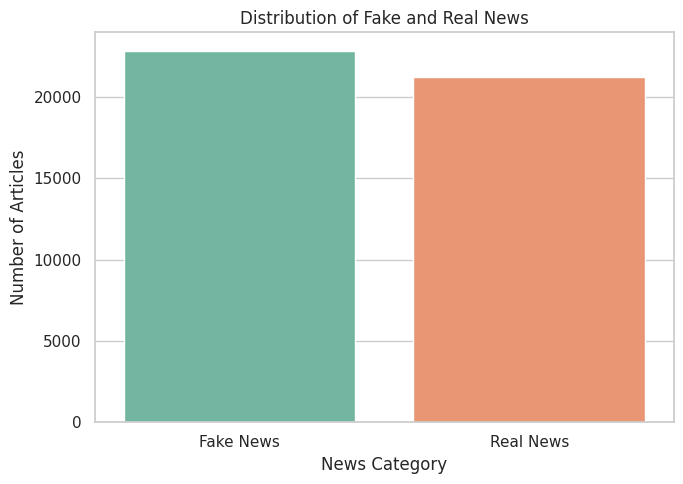

In [31]:
news_counts = news_df["label"].map({
    0: "Fake News",
    1: "Real News"
}).value_counts()

display(news_counts.to_frame("Article Count"))

plt.figure(figsize=(7, 5))
sns.countplot(
    data=news_df,
    x="label",
    hue="label",
    palette="Set2",
    legend=False
)
plt.xticks([0, 1], ["Fake News", "Real News"])
plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

compare article word counts

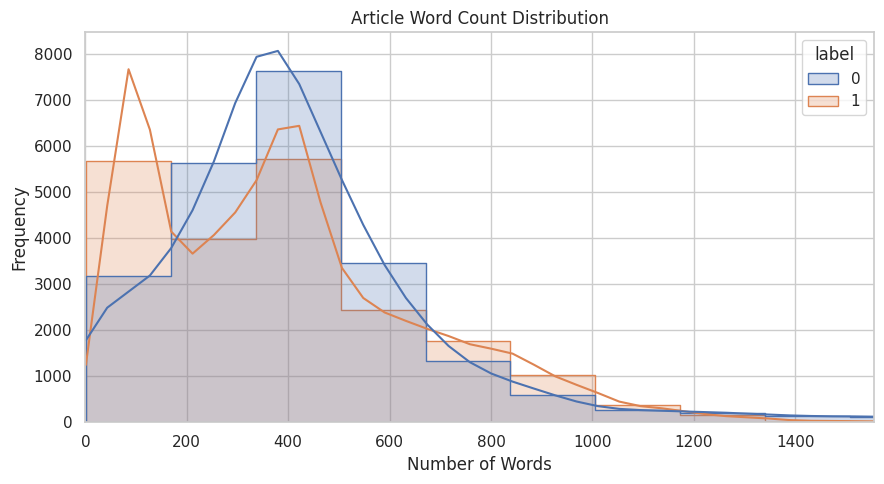

In [32]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=news_df,
    x="word_count",
    hue="label",
    bins=50,
    kde=True,
    element="step"
)
plt.title("Article Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, news_df["word_count"].quantile(0.99))
plt.tight_layout()
plt.show()

compare linguistic features

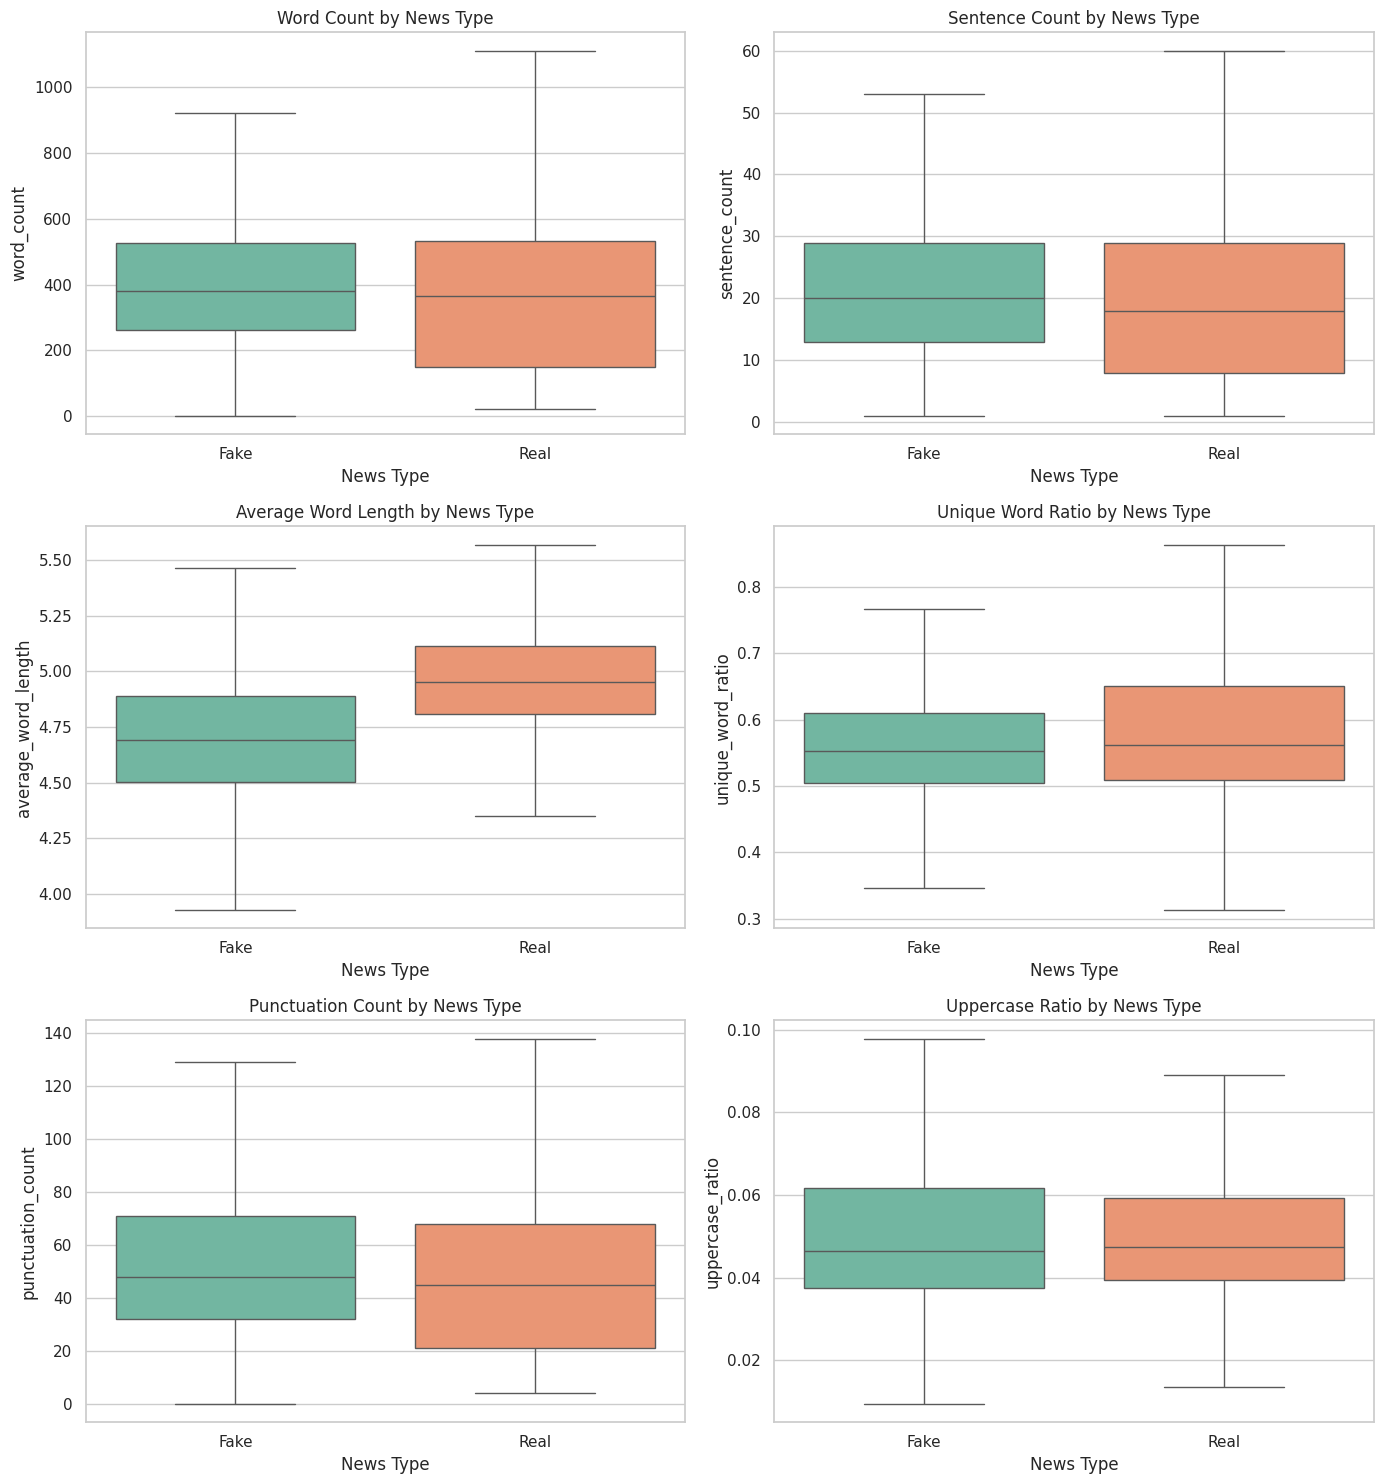

In [33]:
features_to_plot = [
    "word_count",
    "sentence_count",
    "average_word_length",
    "unique_word_ratio",
    "punctuation_count",
    "uppercase_ratio"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.boxplot(
        data=news_df,
        x="label",
        y=feature,
        hue="label",
        palette="Set2",
        legend=False,
        ax=ax,
        showfliers=False
    )
    ax.set_xticks([0, 1], ["Fake", "Real"])
    ax.set_title(f"{feature.replace('_', ' ').title()} by News Type")
    ax.set_xlabel("News Type")

plt.tight_layout()
plt.show()

analyze news subject

In [34]:
print("Available columns:", news_df.columns.tolist())

if "subject" in news_df.columns:
    display(news_df["subject"].value_counts().to_frame("Article Count"))
else:
    print("No subject column available.")

Available columns: ['title', 'text', 'subject', 'date', 'label', 'word_count', 'sentence_count', 'character_count', 'average_word_length', 'unique_word_count', 'punctuation_count', 'uppercase_count', 'uppercase_ratio', 'unique_word_ratio', 'average_sentence_length']


,Article Count
subject,
politicsNews,11219
worldnews,9991
News,9050
politics,6429
left-news,4308
Government News,1498
US_News,783
Middle-east,778


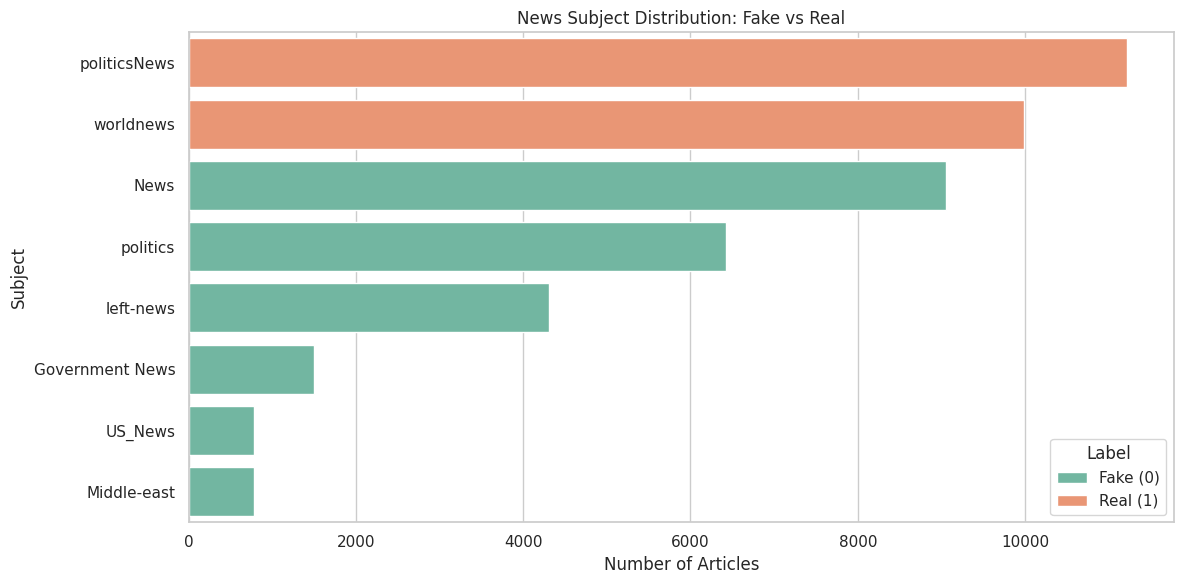

In [35]:
if "subject" in news_df.columns:
    plt.figure(figsize=(12, 6))

    sns.countplot(
        data=news_df,
        y="subject",
        hue="label",
        palette="Set2",
        order=news_df["subject"].value_counts().index
    )

    plt.title("News Subject Distribution: Fake vs Real")
    plt.xlabel("Number of Articles")
    plt.ylabel("Subject")
    plt.legend(title="Label", labels=["Fake (0)", "Real (1)"])
    plt.tight_layout()
    plt.show()

numerical comparison table

In [36]:
eda_summary = news_df.groupby("label")[feature_columns].agg(
    ["mean", "median", "std"]
).round(3)

display(eda_summary)

word_count                 sentence_count                 \
            mean median      std           mean median     std   
label                                                            
0        448.272  381.0  420.655         24.100   20.0  21.435   
1        392.949  366.0  280.708         20.877   18.0  15.943   

      character_count                   average_word_length  ...  \
                 mean  median       std                mean  ...   
label                                                        ...   
0            2616.783  2200.0  2530.625               4.697  ...   
1            2376.751  2215.0  1684.400               4.963  ...   

      uppercase_count uppercase_ratio               unique_word_ratio         \
                  std            mean median    std              mean median   
label                                                                          
0             108.453           0.059  0.046  0.059             0.575  0.553   
1              61.497           0.052  0.047  0.019             0.587  0.562   

             average_sentence_length                 
         std                    mean  median    std  
label                                                
0      0.121                  18.935  18.612  5.650  
1      0.107                  20.103  19.529  5.891  

[2 rows x 30 columns]

In [37]:
news_df.to_csv(
    "/content/fake_news_linguistic_features.csv",
    index=False
)

feature_comparison.to_csv(
    "/content/fake_vs_real_feature_comparison.csv"
)

eda_summary.to_csv(
    "/content/fake_news_eda_summary.csv"
)

print("Saved all three CSV files successfully.")

Saved all three CSV files successfully.


verifying final dataset

In [38]:
print("Final dataset shape:", news_df.shape)

print("\nClass distribution:")
display(
    news_df["label"]
    .map({0: "Fake", 1: "Real"})
    .value_counts()
    .to_frame("Article Count")
)

print("\nMissing values:")
display(news_df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", news_df.duplicated().sum())

print("\nExtracted features:")
display(pd.DataFrame({
    "Feature": feature_columns,
    "Data Type": news_df[feature_columns].dtypes.astype(str).values,
    "Missing Values": news_df[feature_columns].isnull().sum().values
}))

Final dataset shape: (44056, 15)

Class distribution:


,Article Count
label,
Fake,22846
Real,21210



Missing values:


,Missing Values
title,0
text,0
subject,0
date,0
label,0
word_count,0
sentence_count,0
character_count,0
average_word_length,0
unique_word_count,0



Duplicate rows: 0

Extracted features:


,Feature,Data Type,Missing Values
0,word_count,int64,0
1,sentence_count,int64,0
2,character_count,int64,0
3,average_word_length,float64,0
4,unique_word_count,int64,0
5,punctuation_count,int64,0
6,uppercase_count,int64,0
7,uppercase_ratio,float64,0
8,unique_word_ratio,float64,0
9,average_sentence_length,float64,0


In [39]:
handoff_columns = [
    col for col in [
        "title", "text", "subject", "date", "label",
        "word_count", "sentence_count", "character_count",
        "average_word_length", "unique_word_count",
        "punctuation_count", "uppercase_count",
        "uppercase_ratio", "unique_word_ratio",
        "average_sentence_length"
    ]
    if col in news_df.columns
]

handoff_df = news_df[handoff_columns].copy()

handoff_df.to_csv(
    "/content/fake_news_DS_DA_handoff.csv",
    index=False
)

print("Handoff dataset saved successfully.")
print("Shape:", handoff_df.shape)

Handoff dataset saved successfully.
Shape: (44056, 15)


In [40]:
final_quality_report = pd.DataFrame({
    "Metric": [
        "Total articles",
        "Total columns",
        "Fake articles",
        "Real articles",
        "Missing cells",
        "Exact duplicate rows"
    ],
    "Value": [
        len(news_df),
        news_df.shape[1],
        int((news_df["label"] == 0).sum()),
        int((news_df["label"] == 1).sum()),
        int(news_df.isnull().sum().sum()),
        int(news_df.duplicated().sum())
    ]
})

display(final_quality_report)

final_quality_report.to_csv(
    "/content/fake_news_data_quality_report.csv",
    index=False
)

,Metric,Value
0,Total articles,44056
1,Total columns,15
2,Fake articles,22846
3,Real articles,21210
4,Missing cells,0
5,Exact duplicate rows,0
